In [1]:
from quantify_core.data.handling import (
    default_datadir,
    get_latest_tuid,
    get_tuids_containing,
    load_dataset,
    locate_experiment_container,
    set_datadir,
)

import numpy as np
import matplotlib.pyplot as plt

from collections import OrderedDict

import deprecated
import matplotlib.pyplot as plt
import numpy as np
from pyDOE2 import lhs
import itertools
from numpy.typing import NDArray
import xarray as xr
from cmaes import CMA, get_warm_start_mgd
from typing import Tuple, Callable, List, Any, Optional, Dict
from qcodes import Parameter, validators
from quantify_core.measurement.control import MeasurementControl
from quantify_core.measurement.types import Settable, Gettable
from quantify_core.analysis.base_analysis import BaseAnalysis, BasicAnalysis
from quantify_core.visualization.mpl_plotting import set_suptitle_from_dataset
from quantify_core.data.handling import trim_dataset
from quantify_scheduler import Schedule
from quantify_scheduler.enums import BinMode

from quantify_core.analysis.base_analysis import Basic2DAnalysis
from quantify_core.data.handling import to_gridded_dataset, grow_dataset
from qce_utils.support_classes.utilities_array_shaping import (
    pairwise_complex,
    normalize_tensor_dataset,
    recursively_split_and_process_dataset,
)
from qce_utils.addon_quantify.decorator_metadata import metadata_from_function_signature
from qce_utils.addon_quantify.deserialize_xarray_to_obj import (
    DeserializeBootstrap,
    IXarrayBootstrap,
)

from qce_utils.qed_modeling.intrf_state_classification import (
    IQNDPiStateClassifierContainer,
)
from qce_utils.addon_quantify.object_factories.factory_state_acquisition import (
    QNDPiStateClassifierFactory,
    QNDPiStateClassifierContainer,
    QNDPiLandscapeFactory,
    MultiQubitQNDPiStateClassifierFactory,
    MultiQubitQNDPiStateClassifierContainer,
    AcquisitionType,
    MultiQubitQNDPiOptimizationFactory,
    StateKey,
)
from qce_utils.control_interfaces.datastorage_control.analysis_factories.factory_state_classification import (
    StateAxesProjectionAnalysis,
    QNDPiStateClassifierAnalysis,
    QNDPiLandscapeContainer,
    QNDPiLandscapeAnalysis,
    QNDPiAndSNRLandscapeAnalysis,
    LandscapeType,
    FigureContainer,
    QNDPiOptimizationAnalysis,
    MultiQubitReadoutOptimizationContainer,
    IReadoutOptimizationContainer,
    OptimizedReadoutParameters,
)
from qce_interp.interface_definitions.intrf_state_classification import (
    StateBoundaryKey,
    StateKey,
)
from qce_utils.addon_quantify.object_factories.factory_readout_transient import (
    OptimalWeightsFactory,
)
from qce_utils.control_interfaces.datastorage_control.analysis_factories.factory_readout_transient import (
    OptimalWeightsIdentifier,
    ReadoutTransientAnalysis,
    OptimalWeightsAnalysis as OptimalWeightsAnalysis_,
)
# from hqt_utils.operations.gate_library import Identity

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import colorsys

In [2]:
set_datadir(default_datadir())

Data will be saved in:
/home/pschaefers/quantify-data


In [68]:
def process_CMAES_data(dataset, population_size, qubit_names=None, batched_qubit_names=None):
    """
    Processes fidelity data for n qubits based on the given dataset and population size.

    Parameters:
        dataset: An xarray-like object containing data attributes 
                 (e.g., dataset.x0.data, dataset.y0.data, etc.).
        population_size: The size of the population.
        qubit_names: List of qubit names. If None, will try to use dataset.elements.
        batched_qubit_names: Optional list of lists, grouping qubits together.

    Returns:
        A dictionary containing mean and population fidelity data for all qubit_names 
        and optionally for batched_qubit_names.
    """

    if qubit_names is None:
        if hasattr(dataset, "elements"):
            qubit_names = dataset.elements
        else:
            raise ValueError("No qubit names provided and dataset has no 'elements' attribute.")

    fidelity_data = {}

    # Maps descriptive names to dataset keys
    name_to_var = {dataset[var].attrs.get("name"): var for var in dataset.data_vars}
    name_to_coord = {dataset[coord].attrs.get("name"): coord for coord in dataset.coords}

    # Handle batched qubits
    if batched_qubit_names is not None:
        batched_names = ["_".join(qubits) for qubits in batched_qubit_names]

        for batched_name in batched_names:
            obj = dataset[name_to_var.get(f"objective{batched_name}")].values
            fidelity_data[batched_name] = {
                'objective': obj,
                'mean': {'objective': obj[population_size::population_size + 1]},
                'pop': {'objective': np.array([obj[i::population_size + 1] for i in range(population_size)])}
            }

    # Handle individual qubits
    for qubit in qubit_names:
        # Base fidelity data
        fidelity_data[qubit] = {
            'freq': dataset[name_to_coord.get(f"frequency_{qubit}")].values,
            'ampl': dataset[name_to_coord.get(f"amplitude_{qubit}")].values,
            'dur': dataset[name_to_coord.get(f"duration_{qubit}")].values,
            'assignfid_av': dataset[name_to_var.get(f"av_assignment_{qubit}")].values,
            'assignfid_01': dataset[name_to_var.get(f"01_assignment_{qubit}")].values,
            'assignfid_02': dataset[name_to_var.get(f"02_assignment_{qubit}")].values,
            'assignfid_12': dataset[name_to_var.get(f"12_assignment_{qubit}")].values,
            'qndpifid': dataset[name_to_var.get(f"qnd_pi_{qubit}")].values,
        }

        # Mean values
        fidelity_data[qubit]['mean'] = {
            key: fidelity_data[qubit][key][population_size::population_size + 1]
            for key in ['freq', 'ampl', 'dur',
                        'assignfid_av', 'assignfid_01', 
                        'assignfid_02', 'assignfid_12', 'qndpifid']
        }

        # Population values
        fidelity_data[qubit]['pop'] = {
            key: np.array([
                fidelity_data[qubit][key][i::population_size + 1]
                for i in range(population_size)
            ])
            for key in ['freq', 'ampl', 'dur',
                        'assignfid_av', 'assignfid_01', 
                        'assignfid_02', 'assignfid_12', 'qndpifid']
        }

        if batched_qubit_names is None:
            obj = dataset[name_to_var.get(f"objective{qubit}")].values
            fidelity_data[qubit].update({
                'objective': obj
            })
            fidelity_data[qubit]['mean'].update({
                'objective': obj[population_size::population_size + 1]
            })
            fidelity_data[qubit]['pop'].update({
                'objective': np.array([obj[i::population_size + 1] for i in range(population_size)])
            })

    return fidelity_data


In [69]:
nr_generations = 150

tuid_20 = "20250923-072424-900-f27b41"
dataset_20 = load_dataset(tuid=tuid_20)
qubit_names_20 = dataset_20.elements
data_20 = process_CMAES_data(dataset_20,20)

tuid_30 = "20250923-083157-848-fff641"
dataset_30 = load_dataset(tuid=tuid_30)
qubit_names_30 = dataset_30.elements
data_30 = process_CMAES_data(dataset_30,30)

# tuid_40 = "20250923-100922-064-e504ff"
# dataset_40 = load_dataset(tuid=tuid_40)
# qubit_names_40 = dataset_40.elements
# data_40 = process_CMAES_data(dataset_40,40)

tuid_40 = "20250914-110500-690-99f7dd"
dataset_40 = load_dataset(tuid=tuid_40)
qubit_names_40 = dataset_40.elements
data_40 = process_CMAES_data(dataset_40,60, batched_qubit_names=[['D1', 'X1'], ['D3', 'D7', 'D2'], ['X3', 'Z1', 'X2'], ['Z3', 'D5', 'D4'], ['D9', 'D8', 'X4'], ['Z4', 'Z2', 'D6']])

tuid_60 = "20250911-163302-486-9dc2e5"
dataset_60 = load_dataset(tuid=tuid_60)
qubit_names_60 = dataset_60.elements
data_60 = process_CMAES_data(dataset_60,60)

print(qubit_names_20)


['Z3', 'D7', 'D4', 'X3', 'Z1', 'D5']


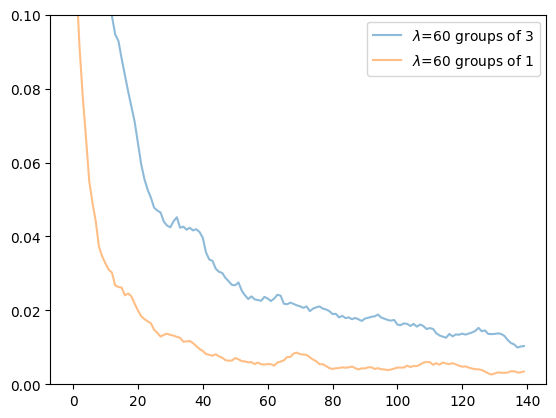

In [76]:
"""
Sweep of population size for a single qubit per object
"""

qubit_names = ['Z3', 'D7', 'X3', 'Z1', 'D5']

ref_freqs = np.array([7617186090.272207, 7085102460.45643, 7301000000.0, 7417371323.858924, 7732470848.240759])-30e6
ref_freqs60 = np.array([7617186090.272207, 7085102460.45643, 7301000000.0, 7417371323.858924, 7721147136.196543])-30e6
ref_ampl = 0.005
ref_dur = 2e-8

objective_20 = 0
objective_30 = 0
objective_40 = 0 
objective_60 = 0 

norm_20 = 0
norm_30 = 0
norm_40 = 0
norm_60 = 0

for i, qubit in enumerate(qubit_names):
    diff_freq_20 = np.abs(np.diff(data_20[qubit]['mean']['freq']/ref_freqs[i]))
    diff_ampl_20 = np.abs(np.diff(data_20[qubit]['mean']['ampl']/ref_ampl))
    diff_dur_20 = np.abs(np.diff(data_20[qubit]['mean']['dur']/ref_dur))

    vector_20 = np.array([diff_freq_20, diff_ampl_20, diff_dur_20]).T
    norm_20 += np.linalg.norm(vector_20, axis=1)/len(qubit_names)

    diff_freq_30 = np.abs(np.diff(data_30[qubit]['mean']['freq']/ref_freqs[i]))
    diff_ampl_30 = np.abs(np.diff(data_30[qubit]['mean']['ampl']/ref_ampl))
    diff_dur_30 = np.abs(np.diff(data_30[qubit]['mean']['dur']/ref_dur))

    vector_30 = np.array([diff_freq_30, diff_ampl_30, diff_dur_30]).T
    norm_30 += np.linalg.norm(vector_30, axis=1)/len(qubit_names)

    diff_freq_40 = np.abs(np.diff(data_40[qubit]['mean']['freq']/ref_freqs[i]))
    diff_ampl_40 = np.abs(np.diff(data_40[qubit]['mean']['ampl']/ref_ampl))
    diff_dur_40 = np.abs(np.diff(data_40[qubit]['mean']['dur']/ref_dur))

    vector_40 = np.array([diff_freq_40, diff_ampl_40, diff_dur_40]).T
    norm_40 += np.linalg.norm(vector_40, axis=1)/len(qubit_names)

    diff_freq_60 = np.abs(np.diff(data_60[qubit]['mean']['freq']/ref_freqs60[i]))
    diff_ampl_60 = np.abs(np.diff(data_60[qubit]['mean']['ampl']/ref_ampl))
    diff_dur_60 = np.abs(np.diff(data_60[qubit]['mean']['dur']/ref_dur))

    vector_60 = np.array([diff_freq_60, diff_ampl_60, diff_dur_60]).T
    norm_60 += np.linalg.norm(vector_60, axis=1)/len(qubit_names)
    
    objective_20 += data_20[qubit]['mean']['objective']/len(qubit_names)
    objective_30 += data_30[qubit]['mean']['objective']/len(qubit_names)
    # objective_40 += data_40[qubit]['mean']['objective']/len(qubit_names)
    objective_60 += data_60[qubit]['mean']['objective']/len(qubit_names)


batched_qubit_names=[['D1', 'X1'], ['D3', 'D7', 'D2'], ['X3', 'Z1', 'X2'], ['Z3', 'D5', 'D4'], ['D9', 'D8', 'X4'], ['Z4', 'Z2', 'D6']]
batched_names = ["_".join(qubits) for qubits in batched_qubit_names]
for batched_name in batched_names:
    objective_40 += data_40[batched_name]['mean']['objective']/len(qubit_names)

scaled_objective_20 = -1/objective_20[1:]*norm_20
scaled_objective_30 = -1/objective_30[1:]*norm_30
scaled_objective_40 = -1/objective_40[1:]*norm_40
scaled_objective_60 = -1/objective_40[1:]*norm_60

N_steps = 10
running_av_so_20 = np.array([np.mean(scaled_objective_20[i:i+N_steps]) for i in range(len(scaled_objective_20)-N_steps+1)])
running_av_so_30 = np.array([np.mean(scaled_objective_30[i:i+N_steps]) for i in range(len(scaled_objective_30)-N_steps+1)])
running_av_so_40 = np.array([np.mean(scaled_objective_40[i:i+N_steps]) for i in range(len(scaled_objective_40)-N_steps+1)])
running_av_so_60 = np.array([np.mean(scaled_objective_60[i:i+N_steps]) for i in range(len(scaled_objective_60)-N_steps+1)])



# plt.plot(running_av_so_20, label=r'$\lambda$=20',alpha=.5)
# plt.plot(running_av_so_30, label=r'$\lambda$=30',alpha=.5)
plt.plot(running_av_so_40, label=r'$\lambda$=60 groups of 3',alpha=.5)
plt.plot(running_av_so_60, label=r'$\lambda$=60 groups of 1',alpha=.5)
plt.ylim(0,0.1)
plt.legend()
plt.show()

In [58]:
def process_CMAES_data(dataset, population_size, qubit_names=None, batched_qubit_names=None):
    """
    Processes fidelity data for n qubits based on the given dataset and population size.

    Parameters:
        dataset: An xarray-like object containing data attributes 
                 (e.g., dataset.x0.data, dataset.y0.data, etc.).
        population_size: The size of the population.
        qubit_names: List of qubit names. If None, will try to use dataset.elements.
        batched_qubit_names: Optional list of lists, grouping qubits together.

    Returns:
        A dictionary containing mean and population fidelity data for all qubit_names 
        and optionally for batched_qubit_names.
    """

    if qubit_names is None:
        if hasattr(dataset, "elements"):
            qubit_names = dataset.elements
        else:
            raise ValueError("No qubit names provided and dataset has no 'elements' attribute.")

    fidelity_data = {}

    # Maps descriptive names to dataset keys
    name_to_var = {dataset[var].attrs.get("name"): var for var in dataset.data_vars}
    name_to_coord = {dataset[coord].attrs.get("name"): coord for coord in dataset.coords}

    # Handle batched qubits
    if batched_qubit_names is not None:
        batched_names = ["_".join(qubits) for qubits in batched_qubit_names]

        for batched_name in batched_names:
            obj = dataset[name_to_var.get(f"objective{batched_name}")].values
            fidelity_data[batched_name] = {
                'objective': obj,
                'mean': {'objective': obj[population_size::population_size + 1]},
                'pop': {'objective': np.array([obj[i::population_size + 1] for i in range(population_size)])}
            }

    # Handle individual qubits
    for qubit in qubit_names:
        # Base fidelity data
        fidelity_data[qubit] = {
            'freq': dataset[name_to_coord.get(f"frequency_{qubit}")].values,
            'ampl': dataset[name_to_coord.get(f"amplitude_{qubit}")].values,
            'dur': dataset[name_to_coord.get(f"duration_{qubit}")].values,
            'assignfid_av': dataset[name_to_var.get(f"av_assignment_{qubit}")].values,
            'assignfid_01': dataset[name_to_var.get(f"01_assignment_{qubit}")].values,
            'assignfid_02': dataset[name_to_var.get(f"02_assignment_{qubit}")].values,
            'assignfid_12': dataset[name_to_var.get(f"12_assignment_{qubit}")].values,
            'qndpifid': dataset[name_to_var.get(f"qnd_pi_{qubit}")].values,
        }

        # Mean values
        fidelity_data[qubit]['mean'] = {
            key: fidelity_data[qubit][key][population_size::population_size + 1]
            for key in ['freq', 'ampl', 'dur',
                        'assignfid_av', 'assignfid_01', 
                        'assignfid_02', 'assignfid_12', 'qndpifid']
        }

        # Population values
        fidelity_data[qubit]['pop'] = {
            key: np.array([
                fidelity_data[qubit][key][i::population_size + 1]
                for i in range(population_size)
            ])
            for key in ['freq', 'ampl', 'dur',
                        'assignfid_av', 'assignfid_01', 
                        'assignfid_02', 'assignfid_12', 'qndpifid']
        }

        if batched_qubit_names is None:
            obj = dataset[name_to_var.get(f"objective{qubit}")].values
            fidelity_data[qubit].update({
                'objective': obj
            })
            fidelity_data[qubit]['mean'].update({
                'objective': obj[population_size::population_size + 1]
            })
            fidelity_data[qubit]['pop'].update({
                'objective': np.array([obj[i::population_size + 1] for i in range(population_size)])
            })

    return fidelity_data


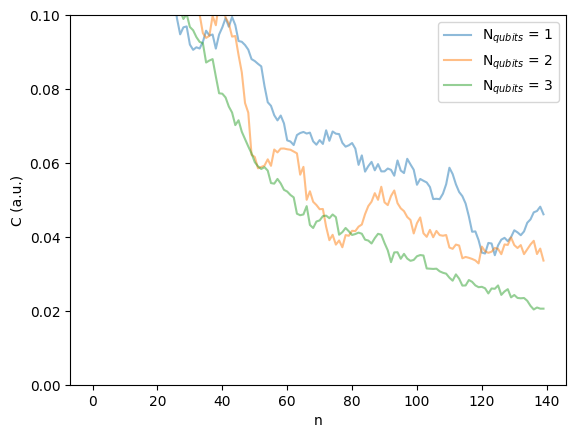

In [75]:
"""
Sweep of population size for a single qubit per object
"""

tuids = ["20250923-083157-848-fff641","20250926-000931-313-ebf59a","20250926-014556-099-a752ba"]
nr_qubits_per_object = [1,2,3]
batched_qubit_names = [None,[['Z3', 'D7'], ['D4', 'X3'], ['Z1', 'D5']],[['Z3', 'D7', 'D4'], ['X3', 'Z1', 'D5']]]

nr_generations = 150
nr_population = 30

ref_freqs_old = np.array([7617186090.272207, 7085102460.45643, 7301000000.0, 7417371323.858924, 7732470848.240759])-30e6
ref_freqs_new = np.array([7.76814347e+09, 7.69970305e+09, 7.27286891e+09, 7.39254336e+09, 7.58696975e+09])
ref_ampl = 0.005
ref_dur = 2e-8

selected_qubit_names = ['Z3', 'D7', 'X3', 'Z1', 'D5']

for j, tuid in enumerate(tuids):
    dataset = load_dataset(tuid=tuid)
    qubit_names = dataset.elements
    
    data = process_CMAES_data(dataset, nr_population, batched_qubit_names=batched_qubit_names[j])
    
    objective = 0
    norm = 0
    
    ref_freqs = ref_freqs_new
    
    for i, qubit in enumerate(selected_qubit_names):
        diff_freq = np.abs(np.diff(data[qubit]['mean']['freq']/ref_freqs[i]))
        diff_ampl = np.abs(np.diff(data[qubit]['mean']['ampl']/ref_ampl))
        diff_dur = np.abs(np.diff(data[qubit]['mean']['dur']/ref_dur))
    
        vector = np.array([diff_freq, diff_ampl, diff_dur]).T
        norm += np.linalg.norm(vector, axis=1)/len(selected_qubit_names)

        if batched_qubit_names[j] is None:
            objective += data[qubit]['mean']['objective']/len(selected_qubit_names)

    if batched_qubit_names[j] is not None:
        batched_names = ["_".join(qubits) for qubits in batched_qubit_names[j]]
        for batched_name in batched_names:
            objective += data[batched_name]['mean']['objective']/len(selected_qubit_names)
    
    scaled_objective = -1/objective[1:]*norm
    
    N_steps = 10
    
    running_av_so = np.array([np.mean(scaled_objective[i:i+N_steps]) for i in range(len(scaled_objective)-N_steps+1)])
    
    plt.plot(running_av_so, label=(r'N$_{qubits}$ = '+f'{nr_qubits_per_object[j]}'),alpha=.5)

plt.xlabel('n')
plt.ylabel('C (a.u.)')
plt.ylim(0,0.1)
plt.legend()
plt.show()